In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('netflix_titles.csv')
df

,S,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [3]:
print("Description: ")
print(df.describe())
print("\nColumn name and types are:")
print(df.info())
#info() method shows the information about the dataframe like non-null count , memory used, columns and data types

Description: 
       release_year
count   8807.000000
mean    2014.180198
std        8.819312
min     1925.000000
25%     2013.000000
50%     2017.000000
75%     2019.000000
max     2021.000000

Column name and types are:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   S             8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB
None


In [6]:
# -------- BEFORE CLEANING --------
print("Shape BEFORE:", df.shape) #- shape: returns number of rows and columns  

print("\nMissing values BEFORE:\n")
print(df.isnull().sum()) #- isnull().sum(): checks no of missing values 

print("\nDuplicate rows BEFORE:", df.duplicated().sum()) #- duplicated(): finds duplicate rows  

Shape BEFORE: (7973, 12)

Missing values BEFORE:

S               0
type            0
title           0
director        0
cast            0
country         0
date_added      9
release_year    0
rating          0
duration        3
listed_in       0
description     0
dtype: int64

Duplicate rows BEFORE: 0


In [7]:
# -------- CLEANING --------

# Fill missing categorical values
df['director'] = df['director'].fillna('Unknown') #- fillna(): fills missing values  
df['cast'] = df['cast'].fillna('Unknown')

# Drop rows with important missing values
df = df.dropna(subset=['country', 'rating']).copy() #- dropna(): removes missing rows  

# Clean string columns (remove extra spaces)
df['country'] = df['country'].str.strip() #- strip(): removes extra spaces 
df['rating'] = df['rating'].str.strip()
df['type'] = df['type'].str.strip()

# Remove duplicates
df = df.drop_duplicates()  #- drop_duplicates(): removes duplicates 


# -------- AFTER CLEANING --------
print("\nShape AFTER:", df.shape)

print("\nMissing values AFTER:\n")
print(df.isnull().sum())

print("\nDuplicate rows AFTER:", df.duplicated().sum())

print("\nSummary AFTER:\n")
print(df.describe(include='all'))  #- describe(): gives summary statistics  


 


Shape AFTER: (7973, 12)

Missing values AFTER:

S               0
type            0
title           0
director        0
cast            0
country         0
date_added      9
release_year    0
rating          0
duration        3
listed_in       0
description     0
dtype: int64

Duplicate rows AFTER: 0

Summary AFTER:

           S   type   title director     cast        country       date_added  \
count   7973   7973    7973     7973     7973           7973             7964   
unique  7973      2    7971     4287     7103            748             1734   
top       s1  Movie  15-Aug  Unknown  Unknown  United States  January 1, 2020   
freq       1   5690       2     2223      671           2818              103   
mean     NaN    NaN     NaN      NaN      NaN            NaN              NaN   
std      NaN    NaN     NaN      NaN      NaN            NaN              NaN   
min      NaN    NaN     NaN      NaN      NaN            NaN              NaN   
25%      NaN    NaN     NaN     

<p style="font-size:18px;"><b>Method Used:</b> Data cleaning techniques such as handling missing values using fillna(), removing rows with missing important values using dropna(), eliminating duplicates using drop_duplicates(), and cleaning noisy data using strip() were applied to improve data quality.</p>

<p style="font-size:18px;"><b>Interpretation:</b> Before cleaning, the dataset contained missing values and duplicate records. After applying cleaning techniques, the dataset became more consistent, with reduced missing values and no duplicates, making it suitable for accurate analysis and visualization.</p>

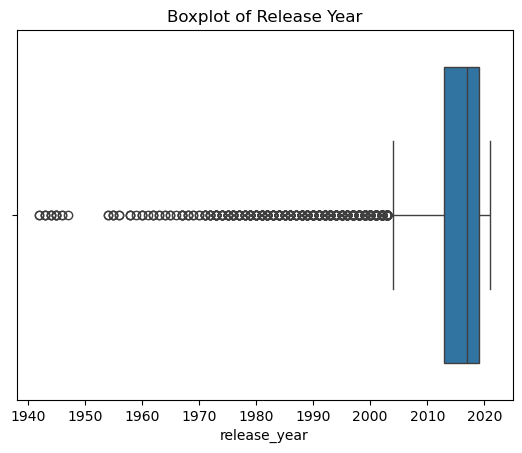

In [8]:
#Q1.Identify outliers in release year using boxplot
sns.boxplot(x=df['release_year'])
plt.title("Boxplot of Release Year")
plt.show()

<p style="font-size:18px;"><b>Graph Choice:</b> Boxplot is used to identify the distribution of release years and detect outliers, as it clearly shows the spread, median, and extreme values in the dataset.</p>

<p style="font-size:18px;"><b>Interpretation:</b> The boxplot highlights that most content is concentrated in recent years, while older release years appear as outliers in the dataset.</p>

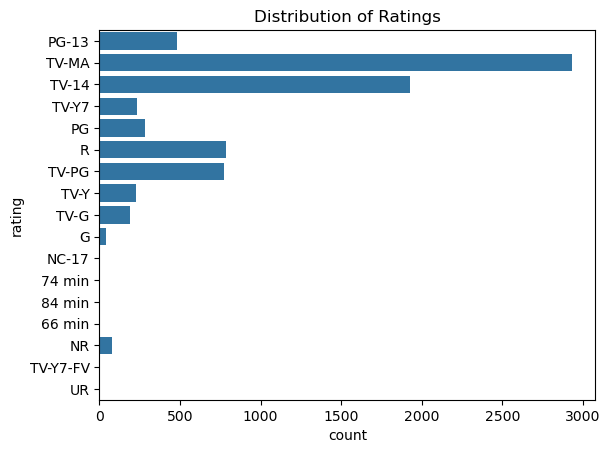

In [7]:
#Q2 .Plot distribution of content ratings
sns.countplot(y='rating', data=df)
plt.title("Distribution of Ratings")
plt.show()

<p style="font-size:18px;"><b>Graph Choice:</b> Countplot is used to visualize the distribution of content ratings, as it effectively shows the frequency of each category.</p>

<p style="font-size:18px;"><b>Interpretation:</b> The graph shows that TV-MA is the most common rating on Netflix, followed by TV-14, indicating that the platform mainly focuses on mature and teen audiences. A few incorrect values like '74 min' appear, suggesting data inconsistency in the rating column.</p>

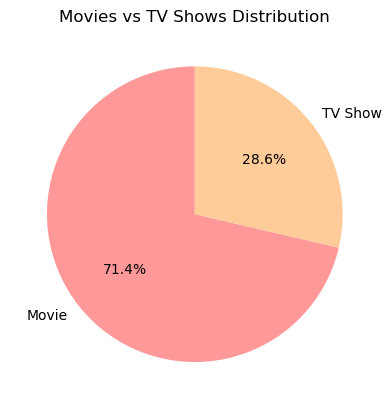

In [8]:
#Show the proportion of Movies and TV Shows using a pie chart
df['type'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    colors=['#ff9999','#ffcc99']
)

plt.title("Movies vs TV Shows Distribution")
plt.ylabel("")
plt.show()

<p style="font-size:18px;"><b>Graph Choice:</b> Pie chart is used to represent the proportion of Movies and TV Shows, as it clearly shows percentage distribution.</p>

<p style="font-size:18px;"><b>Interpretation:</b> The chart shows that Movies make up a larger portion of Netflix content compared to TV Shows, indicating that the platform focuses more on movie content.</p>

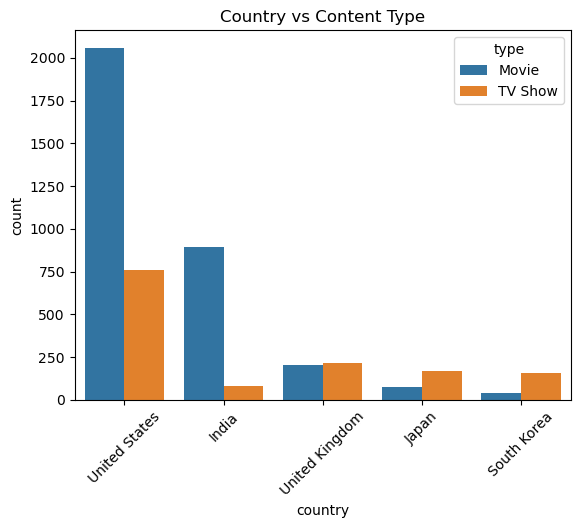

In [9]:
#Q4 Analyze relationship between country and content type
top_countries = df['country'].value_counts().head(5).index
df_top = df[df['country'].isin(top_countries)]

sns.countplot(x='country', hue='type', data=df_top)
plt.xticks(rotation=45)
plt.title("Country vs Content Type")
plt.show()

<p style="font-size:18px;"><b>Graph Choice:</b> Countplot with hue is used to compare the distribution of Movies and TV Shows across different countries, as it clearly shows category-wise comparison within each country.</p>

<p style="font-size:18px;"><b>Interpretation:</b> The graph shows that the United States produces the highest number of both Movies and TV Shows, followed by India. Movies dominate in most countries, while some countries like the United Kingdom and Japan show a relatively balanced distribution between Movies and TV Shows.</p>

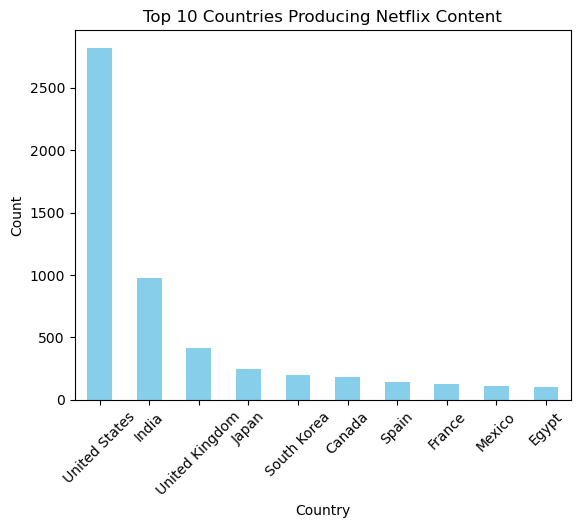

In [15]:
#Q5 Find top 10 countries producing Netflix content
top_countries = df.groupby('country').size().sort_values(ascending=False).head(10)

top_countries.plot(kind='bar', color='skyblue')

plt.title("Top 10 Countries Producing Netflix Content")
plt.xlabel("Country")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

<p style="font-size:18px;"><b>Graph Choice:</b> Bar chart is used to visualize the top 10 countries producing Netflix content, as it clearly compares the frequency of content across different countries.</p>

<p style="font-size:18px;"><b>Interpretation:</b> The bar chart shows that the United States produces the highest amount of Netflix content by a significant margin, followed by India and the United Kingdom. Other countries like Japan, South Korea, and Canada contribute comparatively less. This indicates that Netflix content production is heavily concentrated in a few countries, with the United States dominating the platform.</p>

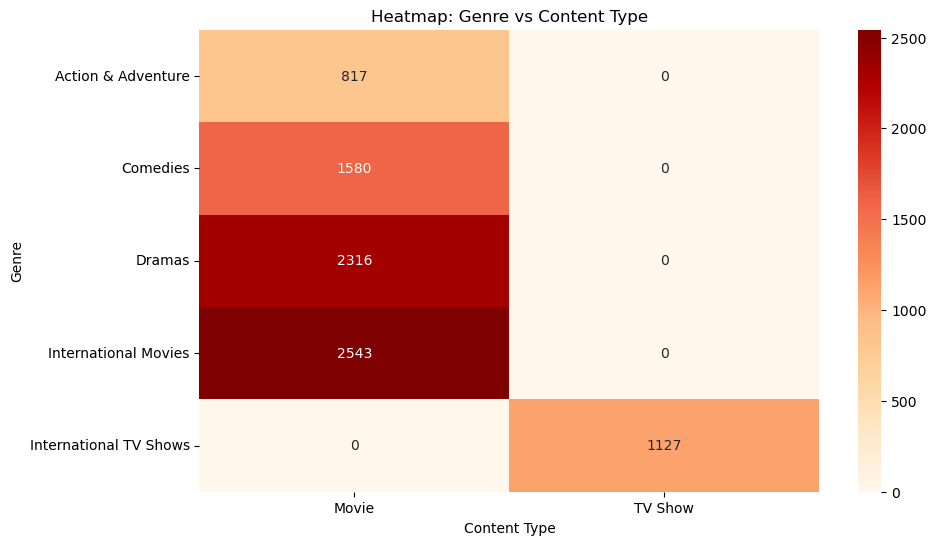

In [11]:
#Q: Analyze the relationship between genres and content type using a heatmap
# split and explode genres
genres = df.copy()
genres['genre'] = genres['listed_in'].str.split(',')
genres = genres.explode('genre')

# clean spaces
genres['genre'] = genres['genre'].str.strip()

# take top 5 genres
top_genres = genres['genre'].value_counts().head(5).index
genres_top = genres[genres['genre'].isin(top_genres)]

# crosstab
tab = pd.crosstab(genres_top['genre'], genres_top['type'])

plt.figure(figsize=(10,6))

sns.heatmap(tab, annot=True, fmt='d', cmap='OrRd')

plt.title("Heatmap: Genre vs Content Type")
plt.xlabel("Content Type")
plt.ylabel("Genre")
plt.show()

<p style="font-size:18px;"><b>Graph Choice:</b> Heatmap is used to analyze the relationship between genres and content types by representing frequencies using color intensity.</p>

<p style="font-size:18px;"><b>Interpretation:</b> The heatmap shows that certain genres like Dramas and International content are more common across multiple content types. The presence of multiple content types within the same entry highlights the diversity of Netflix content.</p>

<p style="font-size:18px;"><b>Graph Choice:</b> Bar plot is used to compare the average release year of Movies and TV Shows, as it clearly shows differences between categories using aggregated values.</p>

<p style="font-size:18px;"><b>Interpretation:</b> The graph shows that TV Shows have a slightly higher average release year compared to Movies, indicating that TV Shows on Netflix tend to be more recent, while Movies include relatively older content.</p>

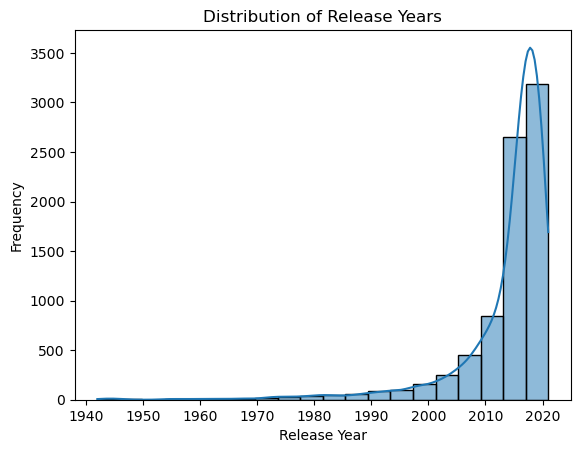

In [14]:
#Q8. Visualize the distribution of release years using histogram
sns.histplot(df['release_year'], bins=20, kde=True)
plt.title("Distribution of Release Years")
plt.xlabel("Release Year")
plt.ylabel("Frequency")
plt.show()

<p style="font-size:18px;"><b>Graph Choice:</b> Histogram with KDE is used to visualize the distribution of release years, as it shows the frequency of data along with the overall trend and density of the dataset.</p>

<p style="font-size:18px;"><b>Interpretation:</b> The graph shows that most Netflix content is concentrated in recent years, especially after 2010, indicating a rapid growth in content production. The KDE curve highlights a peak in recent years, while older years have significantly fewer releases.</p>

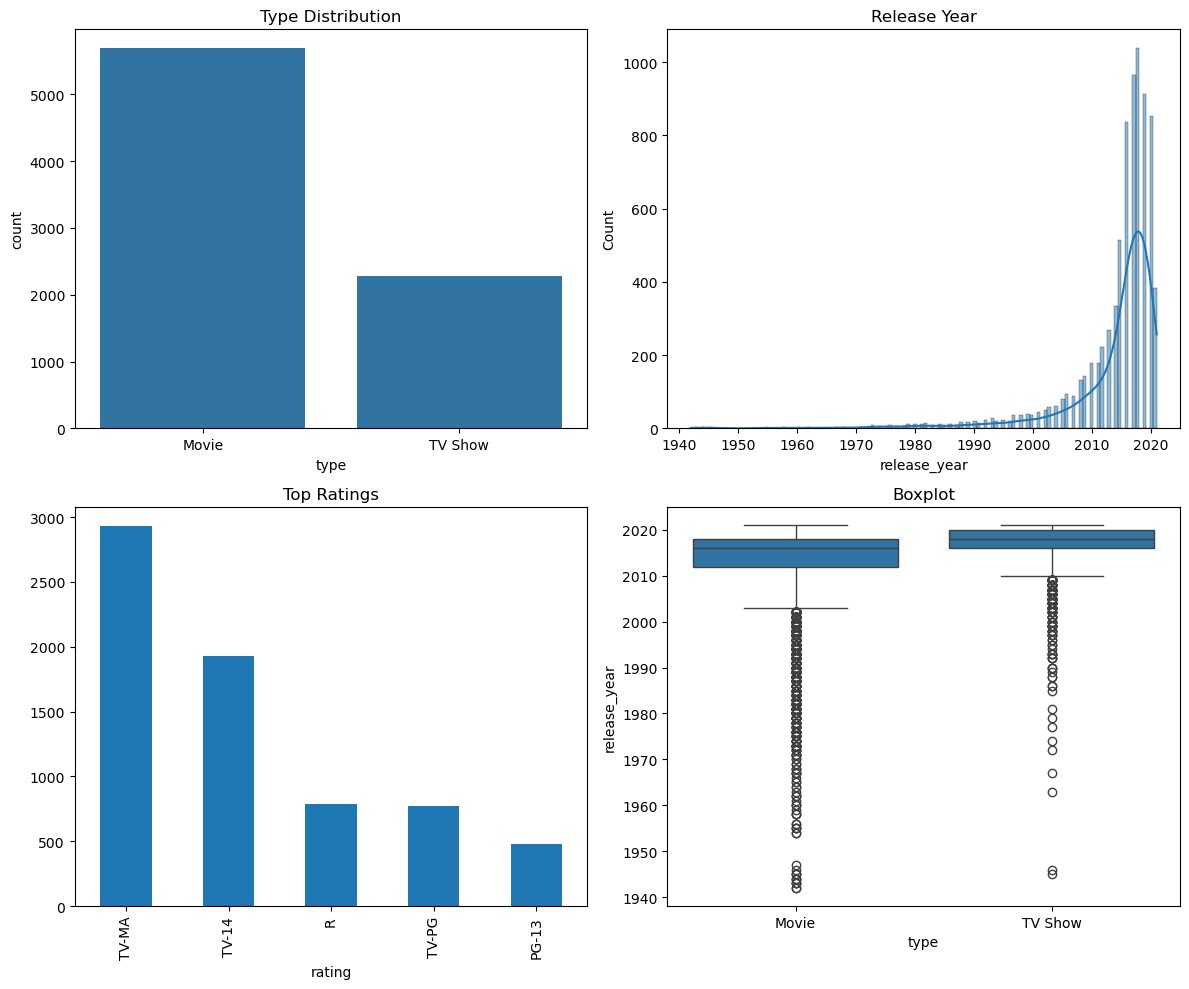

In [15]:
#Q9.
fig, axes = plt.subplots(2, 2, figsize=(12,10))

# Plot 1
sns.countplot(x='type', data=df, ax=axes[0,0])
axes[0,0].set_title("Type Distribution")

# Plot 2
sns.histplot(df['release_year'], kde=True, ax=axes[0,1])
axes[0,1].set_title("Release Year")

# Plot 3
df['rating'].value_counts().head(5).plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title("Top Ratings")

# Plot 4
sns.boxplot(x='type', y='release_year', data=df, ax=axes[1,1])
axes[1,1].set_title("Boxplot")

plt.tight_layout()
plt.show()

<p style="font-size:18px;"><b>Graph Choice:</b> A multi-plot (subplot) layout is used to display multiple visualizations in a single figure, allowing easy comparison of different aspects of the dataset such as content type distribution, release year trends, ratings, and outliers.</p>

<p style="font-size:18px;"><b>Interpretation:</b> The combined plots provide an overall understanding of the dataset. The countplot shows that Movies dominate over TV Shows, the histogram indicates that most content is released in recent years, the bar chart highlights the most common ratings, and the boxplot reveals that older content appears as outliers. Together, these plots give a comprehensive view of Netflix content distribution and trends.</p>

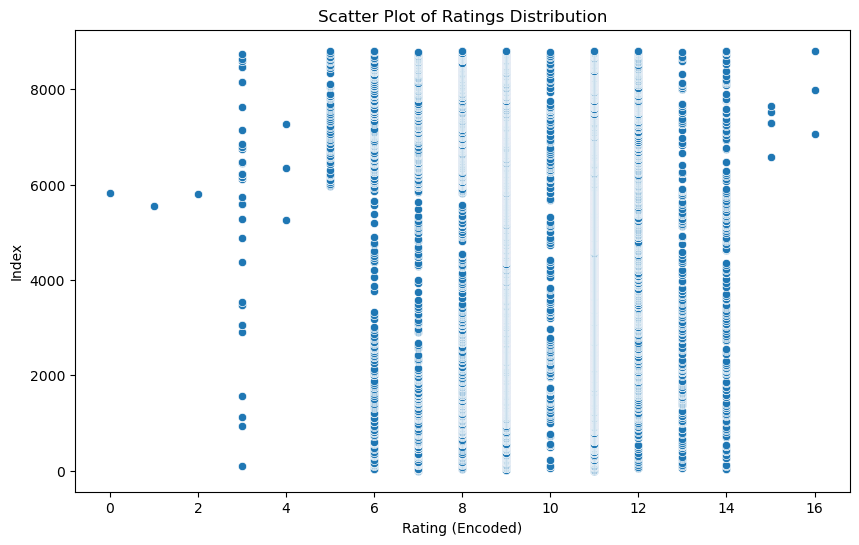

In [12]:
#Q:  Visualize distribution of content ratings using a scatter plot
# convert rating to numeric
df['rating_num'] = df['rating'].astype('category').cat.codes

plt.figure(figsize=(10,6))

sns.scatterplot(x='rating_num', y=df.index, data=df)

plt.title("Scatter Plot of Ratings Distribution")
plt.xlabel("Rating (Encoded)")
plt.ylabel("Index")
plt.show()

<p style="font-size:18px;"><b>Graph Choice:</b> Scatter plot is used to visualize how encoded content types relate to different rating categories, helping to observe distribution and variation across groups.</p>

<p style="font-size:18px;"><b>Interpretation:</b> The plot shows clusters for each rating, with some ratings appearing more frequently, but no clear trend or relationship.</p>

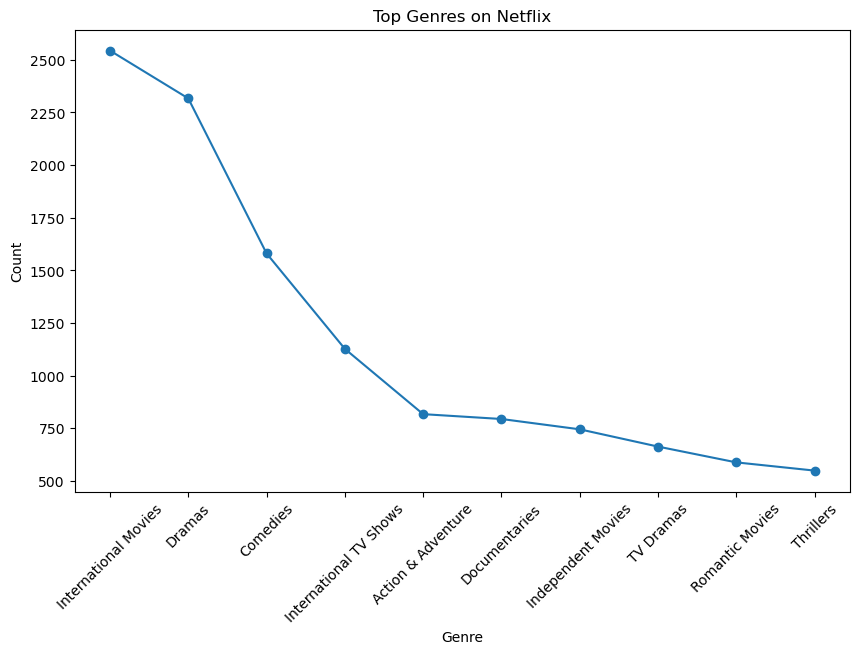

In [20]:
#Q: Visualize the variation of top genres using a line plot
# split genres
genres = df['listed_in'].str.split(',').explode()
genres = genres.str.strip()

top_genres = genres.value_counts().head(10)

plt.figure(figsize=(10,6))

plt.plot(top_genres.index, top_genres.values, marker='o')

plt.title("Top Genres on Netflix")
plt.xlabel("Genre")
plt.ylabel("Count")
plt.xticks(rotation=45)

plt.show()

<p style="font-size:18px;"><b>Graph Choice:</b> Line plot is used to visualize variations in genre frequency across different categories.</p>

<p style="font-size:18px;"><b>Interpretation:</b> The plot shows that certain genres like Drama and International content have higher counts, while other genres appear less frequently, indicating varied content distribution across genres.</p>

In [10]:
#Q10.Split the genre column and analyze most common genres
genres_exploded = df['listed_in'].str.split(',').explode()

genres_exploded.value_counts().head(10)

listed_in
 International Movies     2429
Dramas                    1527
Comedies                  1148
Action & Adventure         817
 Dramas                    789
Documentaries              759
 Independent Movies        725
International TV Shows     615
 TV Dramas                 598
 Romantic Movies           585
Name: count, dtype: int64

<p style="font-size:18px;"><b>Method Used:</b> String manipulation techniques such as split() and explode() are used to separate multiple genres from a single column, enabling accurate analysis of individual genre frequencies.</p>

<p style="font-size:18px;"><b>Interpretation:</b> The results show that 'International Movies' is the most common genre, followed by 'Dramas' and 'Comedies'. This indicates that Netflix content heavily focuses on international and drama-based content, with other genres contributing less comparatively.</p>